# Cross-Disease Analysis & Reliability

**Project modules:** COPD and NAFLD/MASLD  
**Purpose:** Bring together the independently developed disease models, compare their evaluation results, assess reliability, and prepare a consistent output contract for the shared Clinical Decision Support System (CDSS).

## Planned workflow
1. Load the final results exported by the two optimized notebooks.
2. Compare baseline and optimized model metrics.
3. Review disease-specific calibration and reliability results.
4. Inspect model artifacts and metadata.
5. Define a shared prediction-output schema.
6. Document limitations and integration requirements.


## Stage 1: Setup

In [2]:
# ------------------ Stage 1: Setup ------------------

%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

print("Cross-Disease Analysis & Reliability notebook ready.")

Cross-Disease Analysis & Reliability notebook ready.


## Stage 2: Prepare result files

The optimized notebooks currently calculate their metrics in memory. After we review their outputs, we will add small export cells to each notebook so that they save consistent CSV/JSON result files.

Expected files:
- `copd_model_comparison.csv`
- `masld_model_comparison.csv`
- `copd_final_metrics.csv`
- `masld_final_metrics.csv`
- `copd_calibration_results.csv`
- `masld_calibration_results.csv`
- model pipeline and metadata `.pkl` files

For now, this stage checks which files have been uploaded. Do not fabricate or manually estimate missing results.

In [3]:
# ------------------ Stage 2: Upload Final Disease Results ------------------

from google.colab import files

uploaded = files.upload()
uploaded_names = list(uploaded.keys())

print("Uploaded files:")
for name in uploaded_names:
    print("-", name)

required_result_files = [
    "copd_model_comparison.csv",
    "masld_model_comparison.csv",
    "copd_final_metrics.csv",
    "masld_final_metrics.csv",
    "copd_calibration_results.csv",
    "masld_calibration_results.csv"
]

missing = [name for name in required_result_files if name not in uploaded_names]
print("\nMissing result files:", missing if missing else "None")

Saving copd_calibration_results.csv to copd_calibration_results.csv
Saving copd_final_metrics.csv to copd_final_metrics.csv
Saving copd_model_comparison.csv to copd_model_comparison.csv
Saving masld_calibration_results.csv to masld_calibration_results.csv
Saving masld_final_metrics.csv to masld_final_metrics.csv
Saving masld_model_comparison.csv to masld_model_comparison.csv
Uploaded files:
- copd_calibration_results.csv
- copd_final_metrics.csv
- copd_model_comparison.csv
- masld_calibration_results.csv
- masld_final_metrics.csv
- masld_model_comparison.csv

Missing result files: None


## Stage 3: Load and validate disease-level results

This cell loads only the supplied result tables. It does not combine participant-level datasets. If a required file is missing, export it from the corresponding optimized notebook after we verify that notebook's actual outputs.

In [4]:
# ------------------ Stage 3: Load Result Tables ------------------

def load_csv_if_present(filename):
    path = Path(filename)
    if path.exists():
        return pd.read_csv(path)
    print(f"Not found yet: {filename}")
    return None

copd_comparison = load_csv_if_present("copd_model_comparison.csv")
masld_comparison = load_csv_if_present("masld_model_comparison.csv")

copd_final_metrics = load_csv_if_present("copd_final_metrics.csv")
masld_final_metrics = load_csv_if_present("masld_final_metrics.csv")

copd_calibration = load_csv_if_present("copd_calibration_results.csv")
masld_calibration = load_csv_if_present("masld_calibration_results.csv")

print("\nLoaded tables:")
for name, obj in {
    "COPD comparison": copd_comparison,
    "MASLD comparison": masld_comparison,
    "COPD final metrics": copd_final_metrics,
    "MASLD final metrics": masld_final_metrics,
    "COPD calibration": copd_calibration,
    "MASLD calibration": masld_calibration
}.items():
    print(f"{name}: {'loaded' if obj is not None else 'pending'}")


Loaded tables:
COPD comparison: loaded
MASLD comparison: loaded
COPD final metrics: loaded
MASLD final metrics: loaded
COPD calibration: loaded
MASLD calibration: loaded


## Stage 4: Compare baseline and optimized models

In [5]:

# ------------------ Stage 4: Model Comparison ------------------

def add_disease_label(df, disease):
    if df is None:
        return None

    result = df.copy()
    result.insert(0, "Disease", disease)
    return result


comparison_parts = [
    add_disease_label(copd_comparison, "COPD"),
    add_disease_label(masld_comparison, "NAFLD/MASLD")
]

comparison_parts = [
    part for part in comparison_parts if part is not None
]


if comparison_parts:
    cross_disease_comparison = pd.concat(
        comparison_parts,
        ignore_index=True,
        sort=False
    )

    display(cross_disease_comparison)

else:
    print("Comparison pending: upload both disease comparison CSV files.")


# Compare within each disease first. Do not interpret raw metric differences
# as a direct disease difficulty comparison because targets and cohorts differ.

,Disease,Model,Version,Accuracy,Precision,Recall,F1,ROC_AUC,Brier
0,COPD,Logistic Regression,Baseline,0.717833,0.353659,0.753247,0.481328,0.802090,0.195608
1,COPD,Random Forest,Baseline,0.801354,0.396226,0.272727,0.323077,0.730874,0.133132
2,COPD,XGBoost,Baseline,0.828442,0.515152,0.220779,0.309091,0.765684,0.125330
3,COPD,Logistic Regression,Optimized,0.722348,0.358025,0.753247,0.485356,0.803048,0.194986
4,COPD,Random Forest,Optimized,0.693002,0.327485,0.727273,0.451613,0.789032,0.186443
5,COPD,XGBoost,Optimized,0.837472,0.549020,0.363636,0.437500,0.796945,0.129333
6,NAFLD/MASLD,Logistic Regression,Baseline,0.647495,0.401961,0.546667,0.463277,0.646778,0.226316
7,NAFLD/MASLD,Random Forest,Baseline,0.664193,0.357798,0.260000,0.301158,0.595613,0.228946
8,NAFLD/MASLD,XGBoost,Baseline,0.708720,0.452055,0.220000,0.295964,0.655553,0.199144
9,NAFLD/MASLD,Logistic Regression,Optimized,0.647495,0.401961,0.546667,0.463277,0.647172,0.226191


## Stage 5: Visualize disease-specific model performance

The plots below show model metrics by disease. They are descriptive comparisons only: COPD and MASLD have different cohorts, target construction and class distributions, so cross-disease metric differences are not a like-for-like benchmark.

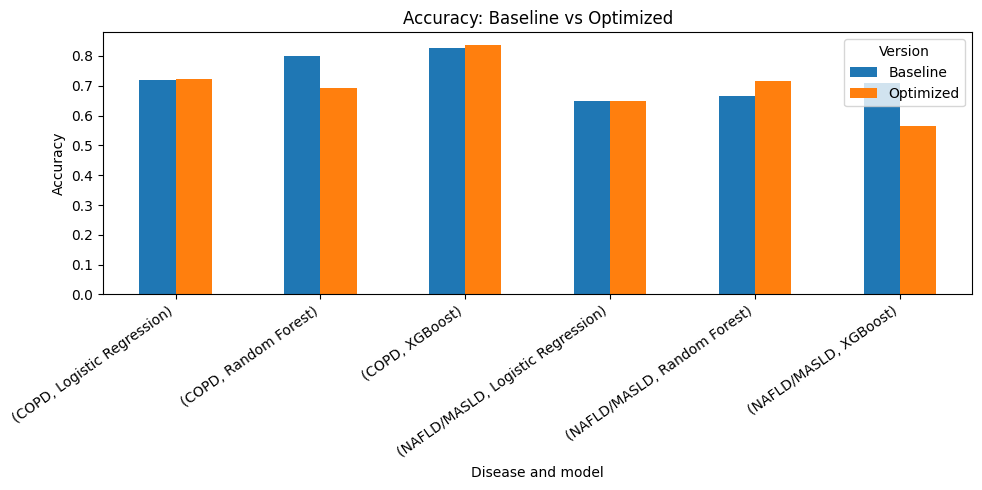

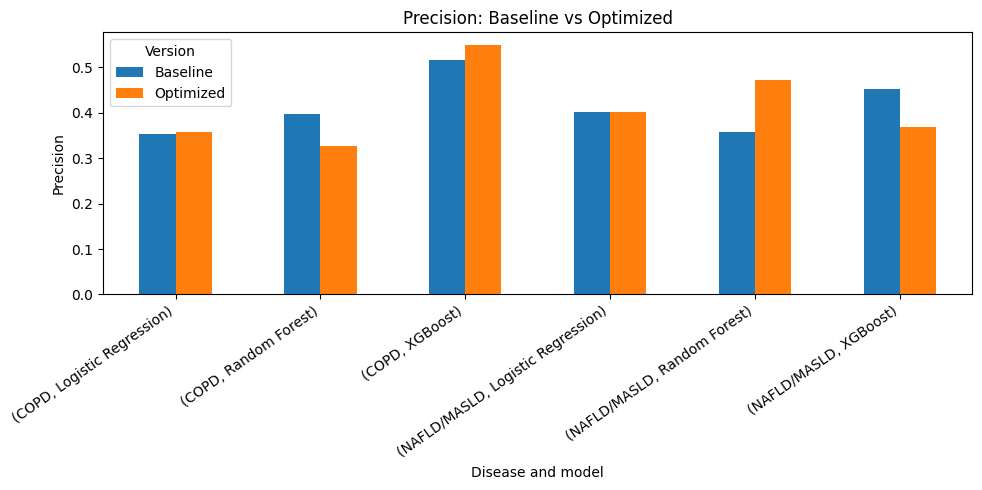

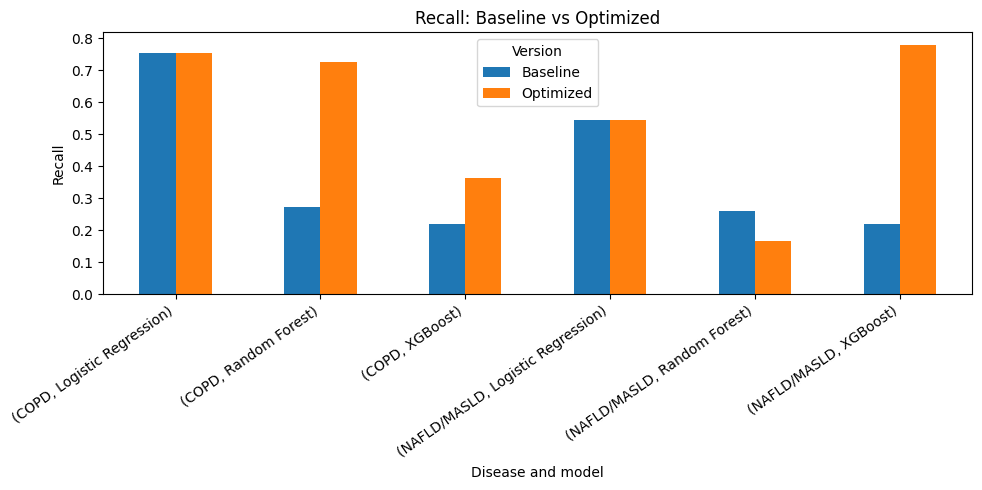

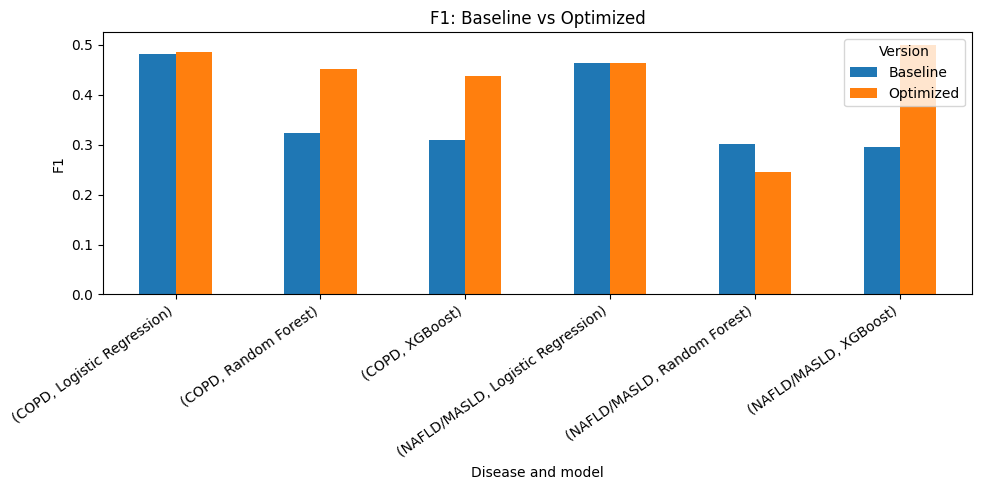

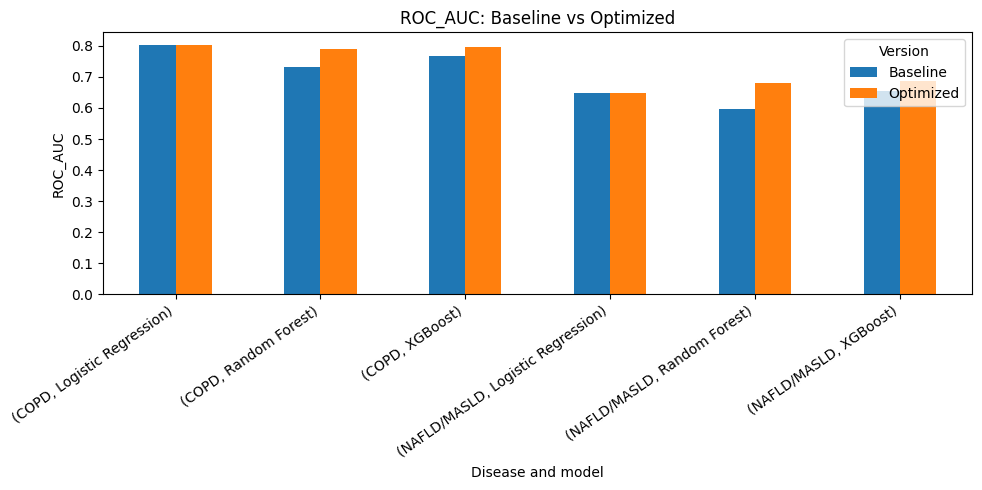

In [6]:
# ------------------ Stage 5: Performance Visualization ------------------

if comparison_parts:
    plot_data = pd.concat(comparison_parts, ignore_index=True, sort=False)
    metric_candidates = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
    available_metrics = [m for m in metric_candidates if m in plot_data.columns]

    for metric in available_metrics:
        plot_data[metric] = pd.to_numeric(plot_data[metric], errors="coerce")
        ax = plot_data.pivot_table(
            index=["Disease", "Model"],
            columns="Version",
            values=metric,
            aggfunc="first"
        ).plot(kind="bar", figsize=(10, 5))
        ax.set_title(f"{metric}: Baseline vs Optimized")
        ax.set_ylabel(metric)
        ax.set_xlabel("Disease and model")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()
else:
    print("Run after both disease result tables are available.")

## Stage 6: Compare probability calibration

In [7]:
# ------------------ Stage 6: Calibration Comparison ------------------

calibration_parts = [
    add_disease_label(copd_calibration, "COPD"),
    add_disease_label(masld_calibration, "NAFLD/MASLD")
]
calibration_parts = [part for part in calibration_parts if part is not None]

if calibration_parts:
    calibration_comparison = pd.concat(
        calibration_parts, ignore_index=True, sort=False
    )
    display(calibration_comparison)

    if "Brier Score" in calibration_comparison.columns:
        calibration_comparison["Brier Score"] = pd.to_numeric(
            calibration_comparison["Brier Score"], errors="coerce"
        )
        display(
            calibration_comparison.pivot_table(
                index="Disease", columns="Model",
                values="Brier Score", aggfunc="first"
            )
        )
else:
    print("Calibration comparison pending result exports.")

print("Interpretation: lower Brier score is generally better, but compare")
print("calibrated vs uncalibrated probabilities within each disease.")

,Disease,Model,Brier Score,ROC-AUC
0,COPD,Uncalibrated,0.194986,0.803048
1,COPD,Sigmoid calibrated,0.116251,0.802942
2,NAFLD/MASLD,Uncalibrated,0.258367,0.687335
3,NAFLD/MASLD,Sigmoid calibrated,0.184056,0.688389


Model,Sigmoid calibrated,Uncalibrated
Disease,,
COPD,0.116251,0.194986
NAFLD/MASLD,0.184056,0.258367


Interpretation: lower Brier score is generally better, but compare
calibrated vs uncalibrated probabilities within each disease.


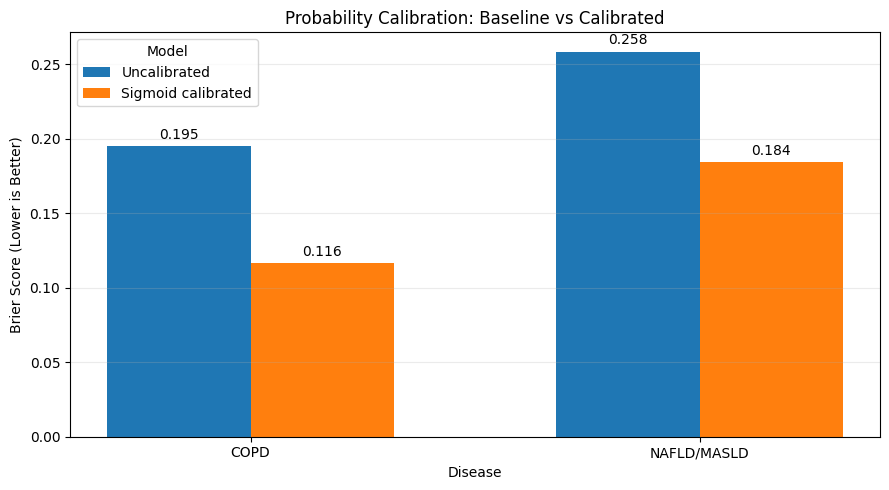

Calibration visualization saved successfully.


In [8]:

# ------------------ Stage 6A: Calibration Visualization ------------------

import matplotlib.pyplot as plt
import numpy as np

if not calibration_parts:
    print("Calibration results are not available.")
else:
    calibration_plot = calibration_comparison.copy()

    calibration_plot["Brier Score"] = pd.to_numeric(
        calibration_plot["Brier Score"], errors="coerce"
    )

    diseases = calibration_plot["Disease"].unique()
    models = ["Uncalibrated", "Sigmoid calibrated"]

    x = np.arange(len(diseases))
    width = 0.32

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, model in enumerate(models):
        values = []

        for disease in diseases:
            row = calibration_plot[
                (calibration_plot["Disease"] == disease) &
                (calibration_plot["Model"] == model)
            ]

            values.append(
                row["Brier Score"].iloc[0] if not row.empty else np.nan
            )

        bars = ax.bar(
            x + (i - 0.5) * width,
            values,
            width,
            label=model
        )

        ax.bar_label(bars, fmt="%.3f", padding=3)

    ax.set_title("Probability Calibration: Baseline vs Calibrated")
    ax.set_ylabel("Brier Score (Lower is Better)")
    ax.set_xlabel("Disease")
    ax.set_xticks(x)
    ax.set_xticklabels(diseases)
    ax.legend(title="Model")
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        "purnendu_calibration_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Calibration visualization saved successfully.")

## Stage 7: Inspect final model artifacts

Upload the final calibrated pipeline and metadata from each optimized notebook. The pipelines remain disease-specific and must be called with their own feature schemas.

In [9]:
# ------------------ Stage 7: Optional Model Artifact Check ------------------

import os
import pickle

artifact_files = {
    "COPD calibrated pipeline": "copd_optimized_calibrated_pipeline.pkl",
    "COPD metadata": "copd_optimized_metadata.pkl",
    "MASLD calibrated pipeline": "masld_optimized_calibrated_pipeline.pkl",
    "MASLD metadata": "masld_optimized_metadata.pkl"
}

loaded_artifacts = {}
artifact_status = []

for name, filename in artifact_files.items():
    if os.path.exists(filename):
        try:
            with open(filename, "rb") as file:
                loaded_artifacts[name] = pickle.load(file)

            artifact_status.append({
                "Artifact": filename,
                "Available": True,
                "Loaded": True
            })

        except Exception as e:
            artifact_status.append({
                "Artifact": filename,
                "Available": True,
                "Loaded": False
            })
            print(f"Could not load {filename}: {e}")

    else:
        artifact_status.append({
            "Artifact": filename,
            "Available": False,
            "Loaded": False
        })

artifact_status_df = pd.DataFrame(artifact_status)

print("Artifact availability:")
display(artifact_status_df)

print(f"Successfully loaded artifacts: {len(loaded_artifacts)} / {len(artifact_files)}")

if len(loaded_artifacts) == 0:
    print("\nNo model artifacts available in this session.")
    print("Continuing with CSV-based cross-disease analysis.")
elif len(loaded_artifacts) < len(artifact_files):
    print("\nSome artifacts are unavailable. CSV-based analysis can continue.")
else:
    print("\nAll expected model artifacts loaded successfully.")

Artifact availability:


,Artifact,Available,Loaded
0,copd_optimized_calibrated_pipeline.pkl,False,False
1,copd_optimized_metadata.pkl,False,False
2,masld_optimized_calibrated_pipeline.pkl,False,False
3,masld_optimized_metadata.pkl,False,False


Successfully loaded artifacts: 0 / 4

No model artifacts available in this session.
Continuing with CSV-based cross-disease analysis.


## Stage 8: Review model metadata and input requirements

In [10]:
# ------------------ Stage 8: Model Metadata ------------------

metadata_found = False

for filename, artifact in loaded_artifacts.items():
    if filename.lower().endswith("metadata.pkl"):
        metadata_found = True
        print(f"\n{filename}")
        print(json.dumps(artifact, indent=2, default=str))

if not metadata_found:
    print("Model metadata unavailable.")
    print("Metadata review skipped because no model artifacts were loaded.")
    print("Input requirements must be obtained from the disease-specific notebooks.")

Model metadata unavailable.
Metadata review skipped because no model artifacts were loaded.
Input requirements must be obtained from the disease-specific notebooks.


## Stage 9: Define the shared CDSS response contract

The shared contract standardizes how each disease module responds. It does not imply that the two diseases use the same features, model, threshold or clinical definition.

The reliability field should be populated only after calibration and uncertainty methodology have been reviewed. Do not label a raw model probability as clinical confidence.

In [11]:
# ------------------ Stage 9: Shared Prediction Response Schema ------------------

shared_response_template = {
    "disease": None,
    "risk": None,
    "probability": None,
    "reliability": None,
    "reliability_reasons": [],
    "missing_inputs": [],
    "conflicts": [],
    "suggested_investigations": [],
    "explanation": [],
    "similar_cases": []
}

print(json.dumps(shared_response_template, indent=2))

{
  "disease": null,
  "risk": null,
  "probability": null,
  "reliability": null,
  "reliability_reasons": [],
  "missing_inputs": [],
  "conflicts": [],
  "suggested_investigations": [],
  "explanation": [],
  "similar_cases": []
}


## Stage 10: Disease-specific target and limitation registry

These definitions must remain visible when integrating predictions into the dashboard.

In [12]:
# ------------------ Stage 10: Target and Limitation Registry ------------------

disease_registry = pd.DataFrame([
    {
        "Disease Module": "COPD",
        "Dataset": "NHANES 2011–2012",
        "Target": "Baseline pre-bronchodilator FEV1/FVC < 0.70",
        "Target Caveat": "Spirometric airflow obstruction; not confirmed COPD diagnosis",
        "Population Caveat": "Selected adults aged 40+ with valid baseline spirometry",
        "Integration Note": "Use COPD-specific feature schema and threshold"
    },
    {
        "Disease Module": "NAFLD/MASLD",
        "Dataset": "NHANES 2017–2018",
        "Target": "Operational CAP >= 302 plus cardiometabolic risk and approximate alcohol eligibility",
        "Target Caveat": "Not a confirmed clinical MASLD diagnosis",
        "Population Caveat": "Selected adults aged 20+ with complete liver exam and labelled target; no survey weights",
        "Integration Note": "Use MASLD-specific feature schema and threshold"
    }
])

display(disease_registry)

,Disease Module,Dataset,Target,Target Caveat,Population Caveat,Integration Note
0,COPD,NHANES 2011–2012,Baseline pre-bronchodilator FEV1/FVC < 0.70,Spirometric airflow obstruction; not confirmed...,Selected adults aged 40+ with valid baseline s...,Use COPD-specific feature schema and threshold
1,NAFLD/MASLD,NHANES 2017–2018,Operational CAP >= 302 plus cardiometabolic ri...,Not a confirmed clinical MASLD diagnosis,Selected adults aged 20+ with complete liver e...,Use MASLD-specific feature schema and threshold


## Stage 11: Cross-Disease Analysis Summary

### 1. Disease Modules
- **COPD:** NHANES 2011–2012; 2,213 participants.
- **NAFLD/MASLD:** NHANES 2017–2018; 2,694 labelled participants.
- Both modules use separate cohorts, feature schemas, and operational targets.

### 2. Best Optimized Models

| Disease | Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---:|---:|---:|---:|---:|
| COPD | XGBoost | 0.8375 | 0.5490 | 0.3636 | 0.4375 | 0.7969 |
| NAFLD/MASLD | XGBoost | 0.5659 | 0.3679 | 0.7800 | 0.5000 | 0.6873 |

- COPD Logistic Regression achieved the highest optimized ROC-AUC (0.8030).
- COPD XGBoost achieved the highest optimized accuracy and precision.
- MASLD XGBoost achieved the highest optimized recall, F1-score, and ROC-AUC.
- Model selection depends on the evaluation metric and disease-specific requirements.

### 3. Calibration

| Disease | Uncalibrated Brier | Calibrated Brier |
|---|---:|---:|
| COPD | 0.194986 | 0.116251 |
| NAFLD/MASLD | 0.258367 | 0.184056 |

- Sigmoid calibration improved Brier scores for both disease modules.
- ROC-AUC remained nearly unchanged after calibration.

### 4. Integration Status
- Shared CDSS response contract defined.
- Disease-specific target and population registry established.
- CSV-based model comparison and calibration analysis completed.
- Model artifacts unavailable in the current session.
- Prediction-level integration and metadata verification remain pending.

### 5. Limitations
- COPD target represents baseline spirometric airflow obstruction, not confirmed COPD.
- MASLD target is operational CAP-based classification, not confirmed clinical MASLD.
- Alcohol eligibility and cardiometabolic indicators use approximate or simplified definitions.
- Fasting glucose and triglycerides are measured in subsamples.
- NHANES survey weights were not incorporated; estimates are not nationally representative.
- The disease modules use different NHANES cycles and populations; participant-level merging is not appropriate.
- Models require external validation and are not clinically ready.

### Conclusion
- Both disease-specific modelling pipelines have completed baseline evaluation, optimization, and calibration analysis.
- Calibration improved probability accuracy in both modules.
- The shared response structure and disease registry provide a foundation for future CDSS integration.
- Actual prediction-level integration remains pending artifact availability and input-schema verification.